# Lesson 04: The readout, part 2: revenue and the business case

Purchases went up. Finance's question is whether that is worth the money: does each email produce more than the **$0.056 of incremental revenue per email** needed to break even ([design doc](../docs/03_experiment_design_doc.md), section 5)?

Revenue per customer is the hardest metric in this experiment: almost everyone spends nothing, and the few who buy spend very different amounts. This lesson covers:

1. what that distribution looks like and why it makes testing hard,
2. two ways to put a confidence interval on revenue: the normal approximation and the bootstrap,
3. why the Mann-Whitney test is the wrong tool here,
4. decomposing revenue into purchases × spend per buyer,
5. the business case against break-even.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from expt.data import load_hillstrom
from expt.inference import bootstrap_diff_in_means, compare_means
from expt.plotting import ARM_COLORS, ARM_LABELS, BAND, INK, INK_2, new_figure, style_axes

df = load_hillstrom()
groups = {arm: df[df["arm"] == arm] for arm in ["control", "mens", "womens"]}
control = groups["control"]

BREAKEVEN = 0.0225 / 0.40      # cost per email / gross margin, from the design doc
GROSS_MARGIN, COST_PER_EMAIL, ACTIVE_FILE = 0.40, 0.0225, 640_000

## 1. What revenue per customer looks like

In [2]:
spend = df["spend"]
print(f"Customers who spent nothing: {(spend == 0).mean():.1%}")
buyers = spend[spend > 0]
print(f"Among buyers: median ${buyers.median():.0f}, mean ${buyers.mean():.0f}, max ${buyers.max():.0f} (the cap from lesson 02)")
print(f"Revenue per customer: mean ${spend.mean():.2f}, SD ${spend.std():.2f}  ->  SD is {spend.std() / spend.mean():.0f}x the mean")

Customers who spent nothing: 99.1%
Among buyers: median $81, mean $116, max $499 (the cap from lesson 02)
Revenue per customer: mean $1.05, SD $15.04  ->  SD is 14x the mean


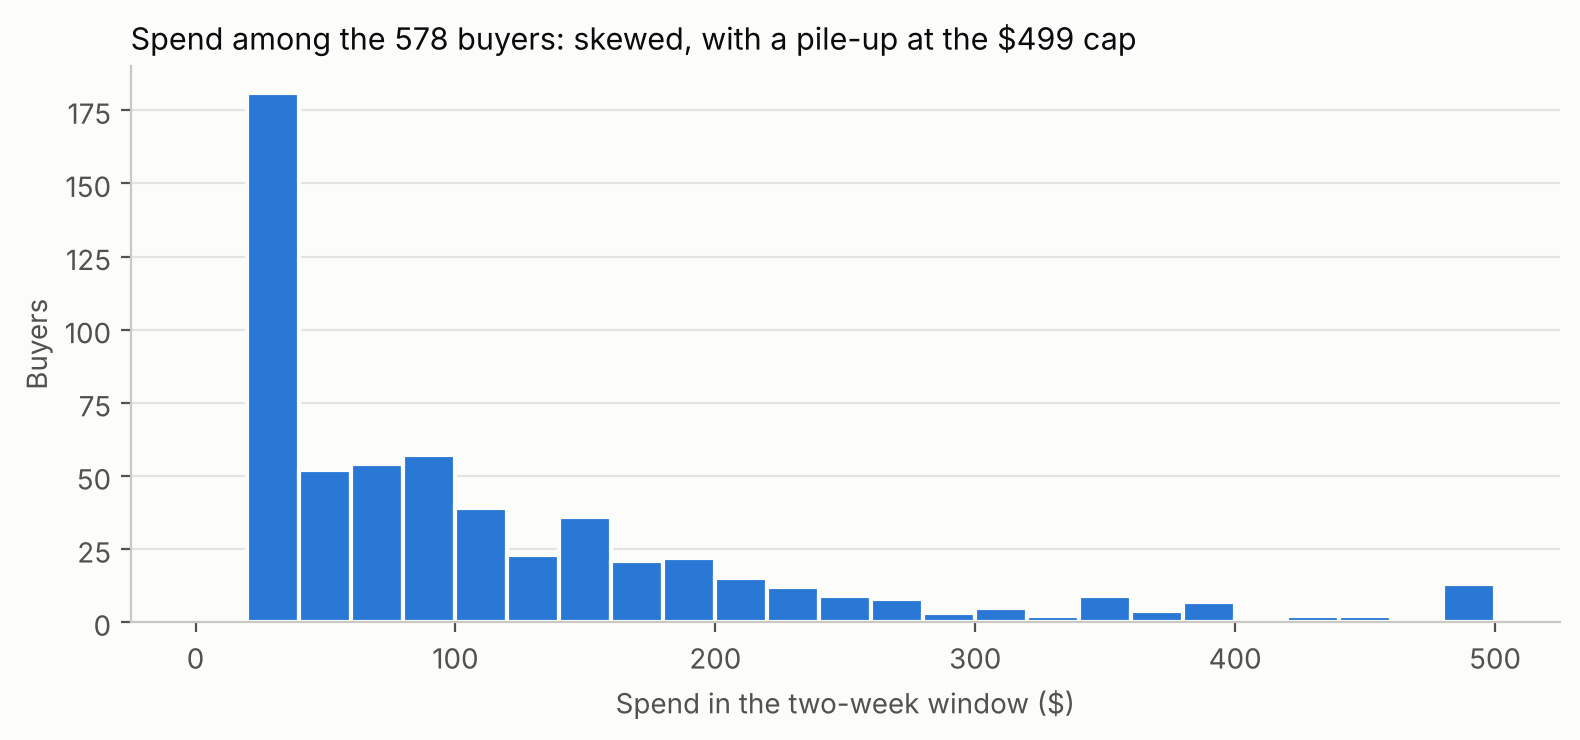

In [3]:
fig, ax = new_figure(8, 3.8)
ax.hist(buyers, bins=np.arange(0, 520, 20), color=ARM_COLORS["mens"], edgecolor="#fcfcfb", linewidth=1.5)
style_axes(ax, title=f"Spend among the {len(buyers)} buyers: skewed, with a pile-up at the $499 cap",
           xlabel="Spend in the two-week window ($)", ylabel="Buyers")
plt.tight_layout()
plt.show()

Over 99% zeros, then a long right tail. With samples this size the average still behaves well enough for the normal approximation, but the spread is so large that revenue estimates are imprecise. That is exactly what the power analysis predicted.

## 2. Revenue lift: normal approximation vs bootstrap

**Welch's interval** uses the normal approximation with each group's own variance. The **bootstrap** makes no such assumption: it resamples customers thousands of times and reads the interval off the resulting distribution. When the two agree, we can trust the simpler one; when they disagree (small samples, extreme skew), the bootstrap is safer.

In [4]:
rows = {}
boots = {}
for arm in ["mens", "womens"]:
    t = groups[arm]["spend"]
    welch = compare_means(t, control["spend"])
    boot = bootstrap_diff_in_means(t, control["spend"], n_boot=2_000, seed=1)
    boots[arm] = boot
    rows[ARM_LABELS[arm]] = {
        "revenue / customer, email": welch.mean_treatment,
        "revenue / customer, no email": welch.mean_control,
        "lift": welch.diff,
        "Welch 95% CI": f"${welch.diff_low:.2f} to ${welch.diff_high:.2f}",
        "bootstrap 95% CI": f"${boot.diff_low:.2f} to ${boot.diff_high:.2f}",
        "p (Welch)": welch.p_value,
    }
pd.DataFrame(rows).T.style.format({"revenue / customer, email": "${:.3f}", "revenue / customer, no email": "${:.3f}",
                                    "lift": "${:+.3f}", "p (Welch)": "{:.1e}"})

,"revenue / customer, email","revenue / customer, no email",lift,Welch 95% CI,bootstrap 95% CI,p (Welch)
Men's e-mail,$1.423,$0.653,$+0.770,$0.49 to $1.05,$0.50 to $1.06,1.2e-07
Women's e-mail,$1.077,$0.653,$+0.424,$0.17 to $0.68,$0.16 to $0.68,1.1e-03


The two methods agree closely: with over 21,000 customers per group the normal approximation holds even for this skewed metric. **The men's email adds about $0.77 per customer, the women's about $0.42.**

## 3. Why not the Mann-Whitney test?

Analysts often reach for the Mann-Whitney (rank-sum) test on skewed data. Look at what it actually tests:

In [5]:
for arm in ["mens", "womens"]:
    _, p_mw = stats.mannwhitneyu(groups[arm]["spend"], control["spend"])
    _, p_conv = stats.chi2_contingency(pd.crosstab(df.loc[df["arm"].isin(["control", arm]), "arm"],
                                                   df.loc[df["arm"].isin(["control", arm]), "conversion"]))[:2]
    print(f"{ARM_LABELS[arm]:>15}: Mann-Whitney p = {p_mw:.1e}   |   purchase-rate test p = {p_conv:.1e}")

   Men's e-mail: Mann-Whitney p = 1.6e-13   |   purchase-rate test p = 2.2e-13
 Women's e-mail: Mann-Whitney p = 1.6e-04   |   purchase-rate test p = 2.0e-04


With 99% ties at zero, the rank test is driven almost entirely by **how many** people bought, not **how much** revenue came in. It answers "does the email shift the distribution?", which is not Finance's question. It would also call a change significant if an email produced more buyers who each spent less, even if total revenue fell. For a decision about money, test the **mean**, which is what revenue is made of.

## 4. Where does the revenue lift come from?

Revenue per customer = purchase rate × spend per buyer:

In [6]:
rows = {}
for arm, g in groups.items():
    rate = g["conversion"].mean()
    per_buyer = g.loc[g["spend"] > 0, "spend"].mean()
    rows[ARM_LABELS[arm]] = {"purchase rate": rate, "spend per buyer": per_buyer, "revenue per customer": rate * per_buyer}
pd.DataFrame(rows).T.style.format({"purchase rate": "{:.3%}", "spend per buyer": "${:.2f}", "revenue per customer": "${:.3f}"})

,purchase rate,spend per buyer,revenue per customer
No e-mail,0.573%,$114.00,$0.653
Men's e-mail,1.253%,$113.53,$1.423
Women's e-mail,0.884%,$121.89,$1.077


Spend per buyer is about the same with or without the men's email ($114); the revenue lift comes almost entirely from **more buyers**. Buyers who got the women's email spend somewhat more per order ($122), but, like purchases among visitors in lesson 03, spend per buyer compares different sets of people, so it is description, not a causal effect. The decision uses revenue per customer over **everyone** in each group.

## 5. The business case

The pre-registered rule: an email pays for itself if its incremental revenue per email reaches the $0.056 break-even.

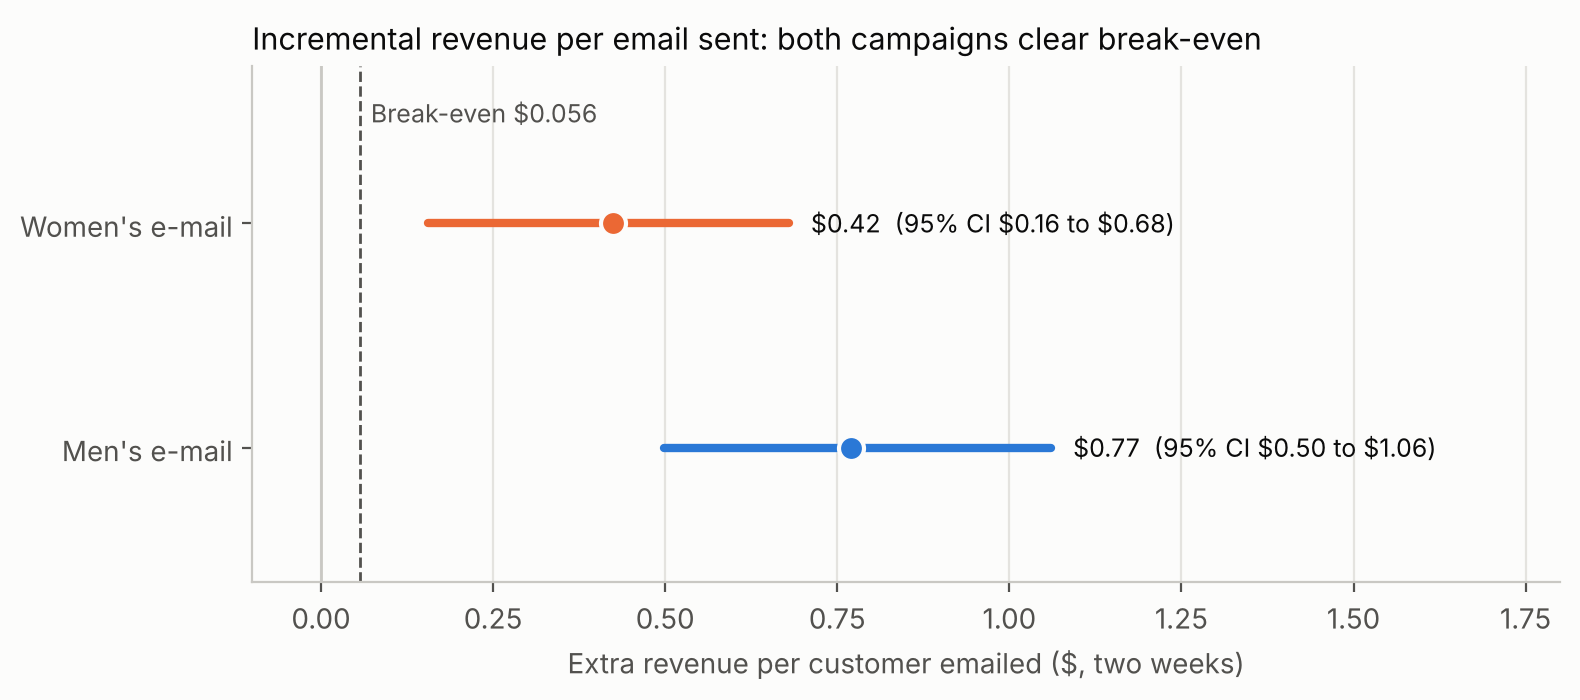

In [7]:
fig, ax = new_figure(8, 3.6)
for i, arm in enumerate(["mens", "womens"]):
    b = boots[arm]
    ax.plot([b.diff_low, b.diff_high], [i, i], color=ARM_COLORS[arm], linewidth=3, solid_capstyle="round")
    ax.plot(b.diff, i, "o", color=ARM_COLORS[arm], markersize=9, markeredgecolor="#fcfcfb", markeredgewidth=1.5)
    ax.annotate(f"${b.diff:.2f}  (95% CI ${b.diff_low:.2f} to ${b.diff_high:.2f})", (b.diff_high, i),
                xytext=(8, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
ax.axvline(BREAKEVEN, color=INK_2, linewidth=1, linestyle="--")
ax.annotate(f"Break-even ${BREAKEVEN:.3f}", (BREAKEVEN, 1.45), xytext=(4, 0), textcoords="offset points",
            color=INK_2, fontsize=9)
ax.axvline(0, color="#c9c8c3", linewidth=1)
ax.set_yticks([0, 1], [ARM_LABELS["mens"], ARM_LABELS["womens"]])
ax.set_ylim(-0.6, 1.7)
ax.set_xlim(-0.1, 1.8)
style_axes(ax, title="Incremental revenue per email sent: both campaigns clear break-even",
           xlabel="Extra revenue per customer emailed ($, two weeks)", grid="x")
plt.tight_layout()
plt.show()

In [8]:
rows = {}
for arm in ["mens", "womens"]:
    b = boots[arm]
    margin = lambda rev: rev * GROSS_MARGIN - COST_PER_EMAIL
    rows[ARM_LABELS[arm]] = {
        "revenue / email": b.diff,
        "x break-even": b.diff / BREAKEVEN,
        "net margin / email": margin(b.diff),
        "net margin per send, full file": margin(b.diff) * ACTIVE_FILE,
        "  low (CI)": margin(b.diff_low) * ACTIVE_FILE,
        "  high (CI)": margin(b.diff_high) * ACTIVE_FILE,
    }
pd.DataFrame(rows).T.style.format({"revenue / email": "${:.3f}", "x break-even": "{:.1f}x", "net margin / email": "${:.3f}",
                                    "net margin per send, full file": "${:,.0f}", "  low (CI)": "${:,.0f}", "  high (CI)": "${:,.0f}"})

,revenue / email,x break-even,net margin / email,"net margin per send, full file",low (CI),high (CI)
Men's e-mail,$0.770,13.7x,$0.285,"$182,676","$113,314","$257,036"
Women's e-mail,$0.424,7.5x,$0.147,"$94,250","$25,288","$159,509"


Even the low ends of the confidence intervals are far above break-even. Sent to the full active file, the men's email would add roughly $180,000 of net margin per send (range about $110,000 to $260,000); the women's roughly $95,000.

**Read these projections with the caveats from the validation report:** only online purchases are counted and spend is capped at $499 (both make the numbers conservative), while the two-week window cannot tell new purchases from purchases pulled forward in time (which would make them optimistic).

### Men's vs women's on revenue

In [9]:
m, w = groups["mens"]["spend"], groups["womens"]["spend"]
diff = bootstrap_diff_in_means(m, w, n_boot=2_000, seed=2)
welch = compare_means(m, w)
print(f"Men's minus women's revenue per email: ${diff.diff:+.3f} "
      f"(bootstrap 95% CI ${diff.diff_low:+.3f} to ${diff.diff_high:+.3f}; Welch p = {welch.p_value:.3f})")

Men's minus women's revenue per email: $+0.345 (bootstrap 95% CI $+0.045 to $+0.660; Welch p = 0.030)


The interval excludes zero, so under the pre-registered rule **the men's email is the winner**. The margin is not huge: the interval runs from a few cents to about $0.66 per email. Lesson 06 checks whether the women's email is nonetheless the better choice for *some* customers.

## Verdict against the pre-registered rules

| Rule | Men's e-mail | Women's e-mail |
|---|---|---|
| Purchase lift significant (Holm)? | Yes | Yes |
| Incremental revenue per email ≥ $0.056? | Yes: $0.77, about 14x | Yes: $0.42, about 7.5x |
| Conclusion | Causes purchases and pays for itself | Causes purchases and pays for itself |
| Winner (CI of difference excludes zero)? | **Yes** | |

## Your turn

**a)** Draw a random 2,000 customers from each of the control and men's groups and compute both the Welch and bootstrap intervals. Repeat a few times. Do they still agree? What changes?

**b)** Suppose spend was not capped at $499 and a few customers spent $5,000. How would the confidence intervals change, and would the decision?

**c)** Finance asks for one number to plan with. Would you give the point estimate ($180,000 per send) or the low end of the interval? Argue both sides in two sentences each.